# 3.1 El Modelo Multidimensional: Construyendo el Espacio
Dejemos atrás las tablas. Vamos a crear un Espacio Vectorial usando `numpy` y `pandas` para entender cómo los modelos de aprendizaje "observa" a nuestros usuarios.

## Formalización

De acuerdo con la literatura matemática estándar, a partir de hoy dejaremos de llamarles 'tablas'. Las llamaremos Matrices de Características (Feature Matrices).

$$\mathbf{X} \in \mathbb{R}^{n \times p}$$
Donde:
* $n$: Representa el número total de observaciones (sus usuarios o filas).
* $p$: Representa la dimensionalidad del espacio (sus variables, features o columnas).

$$\mathbf{X} = \begin{pmatrix} x_{11} & x_{12} & \dots & x_{1p} \\ x_{21} & x_{22} & \dots & x_{2p} \\ \vdots & \vdots & \ddots & \vdots \\ x_{n1} & x_{n2} & \dots & x_{np} \end{pmatrix}$$

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definimos las dimensiones del modelo (Notación ISLP)
n = 5 # Número de observaciones (Usuarios)
p = 3 # Dimensionalidad (Features: Edad, Salario_USD, Engagement_Score)

# Construimos la Matriz X (n x p) con datos de juguete
X_matriz = np.array([
    [25, 3000, 8.5],  # Usuario 1: Vector en 3D
    [45, 8000, 4.2],  # Usuario 2
    [22, 1500, 9.8],  # Usuario 3
    [35, 5000, 6.1],  # Usuario 4
    [28, 4200, 7.5]   # Usuario 5
])

# Para comodidad humana, la envolvemos en un DataFrame
df_X = pd.DataFrame(X_matriz, columns=['Edad', 'Salario', 'Engagement'], 
                    index=['U1', 'U2', 'U3', 'U4', 'U5'])

print("Nuestra Matriz Multidimensional X (n=5, p=3):")
display(df_X)

Nuestra Matriz Multidimensional X (n=5, p=3):


,Edad,Salario,Engagement
U1,25.0,3000.0,8.5
U2,45.0,8000.0,4.2
U3,22.0,1500.0,9.8
U4,35.0,5000.0,6.1
U5,28.0,4200.0,7.5


### Navegando el Espacio Multidimensional
Para la computadora, averiguar si dos usuarios son "similares" no requiere un montón de condicionales `if-else`. Solo requiere **Álgebra Lineal**. Vamos a medir la distancia euclidiana entre el Usuario 1 y el Usuario 3 en este espacio tridimensional.

In [ ]:
# Extrayendo los vectores de los usuarios
vector_u1 = X_matriz[0] # [25.   3000.   8.5]
vector_u3 = X_matriz[2] # [22.   1500.   9.8]

print(f"Coordenadas Usuario 1: {vector_u1}")
print(f"Coordenadas Usuario 3: {vector_u3}")

# Calculando la distancia euclideana multidimensional pura (Norma L2)
distancia = np.linalg.norm(vector_u1 - vector_u3)

print(f"\nLa distancia geométrica exacta entre estos dos usuarios es: {distancia:.2f} unidades.")
print("*(Nota mental: ¿Notan cómo el salario está dominando el cálculo? ¡Por eso vimos el escalamiento la semana pasada!)*")

Coordenadas Usuario 1: [  25.  3000.     8.5]
Coordenadas Usuario 3: [  22.  1500.     9.8]

La distancia geométrica exacta entre estos dos usuarios es: 1500.00 unidades.
*(Nota mental: ¿Notan cómo el salario está dominando el cálculo? ¡Por eso vimos el escalamiento la semana pasada!)*


### El Proyector a la Dimensión Física
Los humanos solo podemos ver hasta 3 dimensiones. Vamos a proyectar nuestra matriz $\mathbf{X}$ en un cubo para entender visualmente dónde está flotando cada usuario.

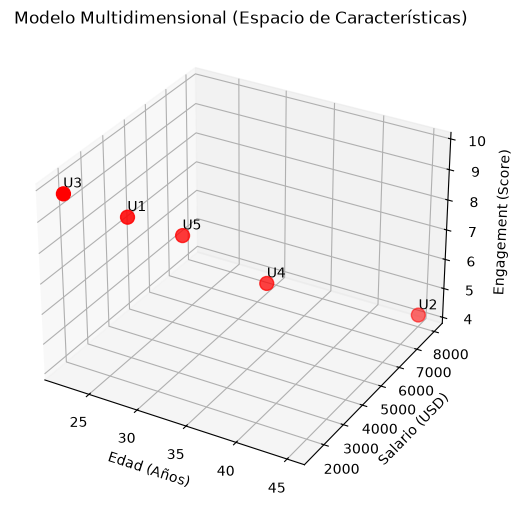

In [5]:
# Graficando el espacio 3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Extraemos los ejes
x = df_X['Edad']
y = df_X['Salario']
z = df_X['Engagement']

# Ploteamos los puntos
scatter = ax.scatter(x, y, z, c='red', s=100, marker='o')

# Etiquetas del espacio
ax.set_xlabel('Edad (Años)')
ax.set_ylabel('Salario (USD)')
ax.set_zlabel('Engagement (Score)')
ax.set_title('Modelo Multidimensional (Espacio de Características)')

# Etiquetamos a cada usuario flotando
for i, txt in enumerate(df_X.index):
    ax.text(x[txt], y[txt], z[txt] + 0.2, txt, size=10, zorder=1, color='k')

plt.show()

---
### Manos a la obra (Responde aquí mismo)

**1. Mutación de la Matriz:**
Si el día de mañana el equipo de desarrollo de la app decide trackear 4 nuevas métricas de comportamiento (clicks, tiempo en pantalla, likes, compartidos) para nuestros mismos 5 usuarios, ¿cuáles serían los nuevos valores exactos de $n$ y $p$ para nuestra matriz $\mathbf{X}$?

> **Tu respuesta:** _N = 5, cada metrica nueva es una columna adicional, por lo tanto p = 7. Aquí estaríamos en un escenario de alta dimensionalidad, porque hay más dimensiones que registros p > n, lo que obligaría a reducir la dimensionalidad si o si_



**2. El Bug Geométrico:**
En la celda de cálculo de distancia euclidiana, notamos que la diferencia de salario (1500 de diferencia) aportó casi el 99% del valor de la distancia final, haciendo que la diferencia de edad (3 años) fuera matemáticamente invisible. ¿Qué técnica exacta de la Unidad II olvidamos aplicar sobre la matriz $\mathbf{X}$ antes de calcular la Norma L2 (Distancia Euclideana)?

> **Tu respuesta:** _Aplicar el método de Estandarización Z-Score, así ninguna variable domina por completo, aplastando a las otras solo por su escala, arreglando la distancia Euclidiana_

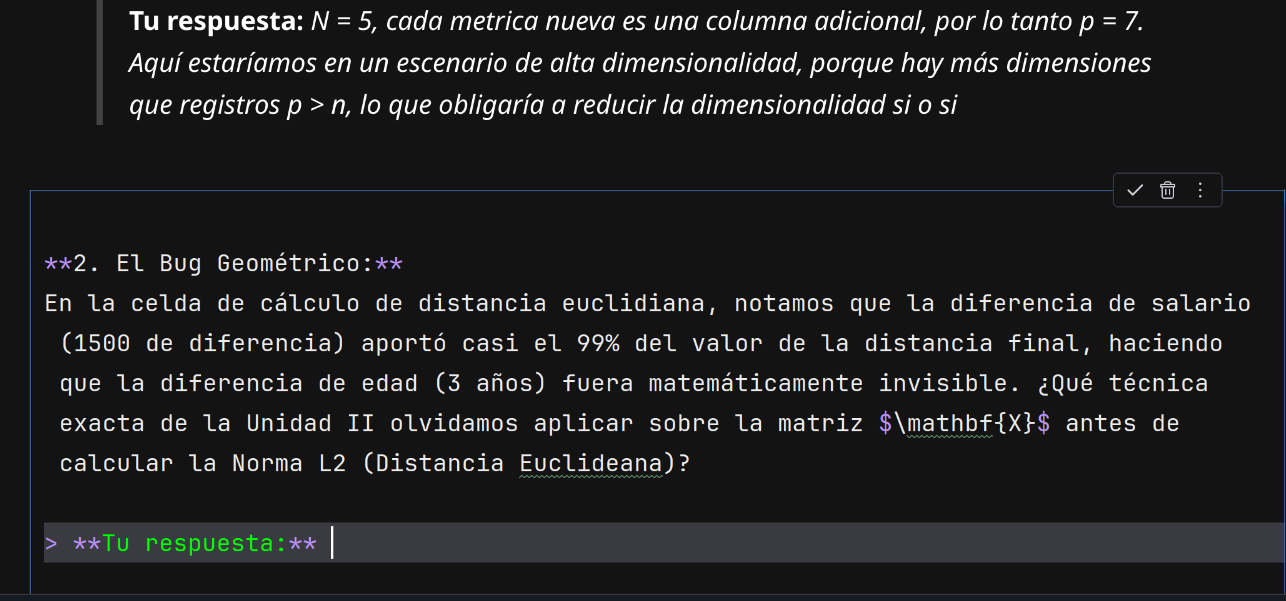


**3. El Límite Humano vs. Máquina:**
En el gráfico 3D pudimos visualizar perfectamente a los usuarios flotando. Si nuestra matriz de características tuviera $p=500$ columnas (por ejemplo, los píxeles de una foto de perfil), ¿cómo procesa la red neuronal este espacio de 500 dimensiones si físicamente no se puede graficar?

> **Tu respuesta:** _La diferencia es que para un humano es imposible que pueda dibujar un punto en un gráfico 3D con 500 coordenadas, lo cual también sería un poco díficil de viualizar, pero para una red neuronal, o una computadora, lo ería como un vector normal, una lista de números, porque en sí no ve en 3D, sino solo números, operar sobre esas 500 columnas sería igual que unos registros con 3 columnas, solo requerirá más calculos_



**4. Eficiencia de Cómputo (Vectores vs Ciclos For):**
Como ingeniero de software, ¿por qué es computacionalmente más eficiente y rápido calcular la distancia entre miles de usuarios utilizando álgebra lineal (tensores con `numpy`) en lugar de extraer los datos y usar bucles `for` anidados para iterar sobre cada fila?

> **Tu respuesta:** _En un ciclo $for$ se tiene que interpretar cada iteración y revisar los tipos de cada elemento, lo cual es muy tardado. Numpy por otro lado vectoriza la operación, ejecuta los ciclos de forma contigua en memoria, sin tener que volverlos a interpretar una y otra vez._